# Практика 2 · Тюмень: обновлённые школы и население

Актуальный выполненный обзор **сохранённых** этапов и показателей. Выполнение этого ноутбука не скачивает город, не меняет исходные данные, не пересчитывает матрицу или модель и не запускает поиск школ. Выводы и изображения получаются из уже рассчитанных файлов. Учебная версия BlocksNet — **1.0.0a9**.

Прежний полный код подготовки данных сохранён в `tyumen_pipeline_refined_previous.ipynb` как **исторический**: он использует прежние правила распознавания жилья и школьные точки. Не запускайте его поверх обновлённых результатов. Актуальные исправления воспроизводятся скриптами `classify_housing.py`, `recalculate_population.py`, `update_schools_csv.py`; они выполняют расчёт и записывают данные, поэтому **не вызываются этим отчётом**.

План: территория → землепользование → здания и население → 82 школы → матрица → обеспеченность → плотности → морфотипы → доступность → выводы и HTML. Данные — локальный OSM/PBF и проверенный пользователем CSV. Условные и восстановленные значения не являются официальной статистикой.

Основные запросы пользователя, определившие обновление: «Используй приложенный CSV как новый основной набор школ»; «сохранив координаты и оценочную вместимость каждого здания»; «есть кварталы с частной жилой застройкой, которые тоже отображаются по нулям». Исправления населения и школ описаны в аудитах, метод распределения мест сохранён.

**Оговорка к заданию:** исторический пешеходный граф собран из локального OSM, а не скачан готовым, как сформулировано в практике 2. Интермодальный граф не используется. Матрица и сценарии относятся именно к этой сети; замена графа требует нового расчёта. Ссылка на [пример BlocksNet](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb).

## 1. Окружение и сохранённые входы
Выберите Python из `python-package-boilerplate/.venv-blocksnet`. Ноутбук запускается из папки проекта или `examples`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display, Markdown

EXAMPLES = Path.cwd()
if not (EXAMPLES / "data_tyumen/refined").is_dir():
    EXAMPLES = EXAMPLES / "examples"
DATA = EXAMPLES / "data_tyumen/refined"
assert DATA.is_dir(), "Откройте ноутбук из папки обновлённой практики 2."
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
results = pd.read_csv(DATA / "results_table.csv", index_col=0)
blocks = gpd.read_file(DATA / "blocks_refined.geojson").set_index("id")
schools = gpd.read_file(DATA / "schools.geojson").set_index("id")
provision = pd.read_csv(DATA / "provision_schools.csv", index_col=0)
density = pd.read_csv(DATA / "density_indicators.csv", index_col=0)
links = pd.read_csv(DATA / "provision_links.csv")
assert len(blocks) == len(results) == 12805 and blocks.index.is_unique
pd.testing.assert_index_equal(results.index, blocks.index, check_names=False, exact=False)
print("Данные:", DATA)
print("Режим: чтение готовых результатов; расчёты модели не запускаются.")

Данные: D:\Рабочий стол\ITMO AI\python-package-boilerplate-updated\examples\data_tyumen\refined
Режим: чтение готовых результатов; расчёты модели не запускаются.


## 2. Территория, кварталы и землепользование
Кварталы выделены ранее BlocksNet, крупные полигоны дополнительно разделены по жилой застройке. Территория и идентификаторы в обновлении не менялись. Доли функциональных зон могут перекрываться, поэтому не интерпретируются как непересекающийся баланс площади.

In [2]:
display(pd.DataFrame({"Значение": [len(blocks), round(blocks.geometry.area.sum()/1e6, 2), str(blocks.crs)]}, index=["Кварталов", "Площадь кварталов, км²", "Проекция"]))
display(results["land_use"].value_counts(dropna=False).rename("Кварталов").to_frame())
display(results[["residential", "business", "recreation", "industrial", "transport", "special", "agriculture"]].describe().round(3))

,Значение
Кварталов,12805
"Площадь кварталов, км²",449.76
Проекция,EPSG:32641


,Кварталов
land_use,
NaN,5252
residential,4988
industrial,1148
recreation,927
business,235
agriculture,136
special,117
transport,2


,residential,business,recreation,industrial,transport,special,agriculture
count,12805.000,12805.000,12805.000,12805.000,12805.000,12805.000,12805.000
mean,0.330,0.015,0.032,0.075,0.000,0.008,0.006
std,0.439,0.115,0.111,0.251,0.003,0.077,0.064
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,0.849,0.000,0.000,0.000,0.000,0.000,0.000
max,2.000,1.000,1.333,1.360,0.266,1.000,1.000


## 3. Здания и модель населения
Население оценено по жилой площади при 30 м² на жителя. Жилое назначение восстановлено для части многоэтажных и частных зданий по сохранённым признакам OSM и контексту. Неизвестность назначения и отсутствие зданий в наборе не доказывают отсутствие жителей. Статусы и изменения сохранены в аудитах.

,Значение
"Население после исправления, модельных жителей",1197166
Прежняя оценка,980707
"Кварталов, где ноль восстановлен в положительное значение",1417
"Квартал 645, жителей",981


,Кварталов
population_status,
no_building_data,5524
estimated_with_unresolved_buildings,1674
estimated_with_housing_inference,1536
unresolved_housing,1507
estimated_from_osm_housing,1420
no_identified_housing,1144


Основания: housing_classification_audit.csv, population_block_changes.csv, population_repair_report.json


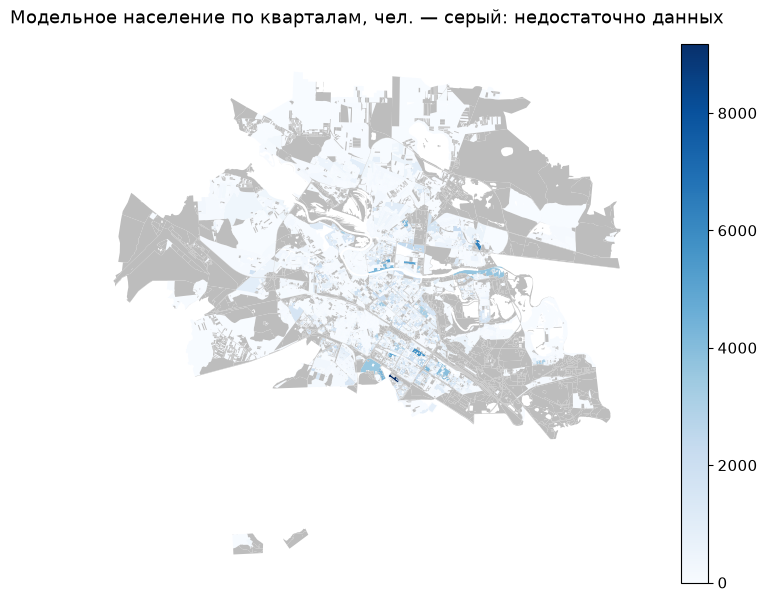

In [3]:
population_report = json.loads((DATA / "population_repair_report.json").read_text(encoding="utf8"))
assert int(results.population.sum()) == 1197166
assert int(results.loc[645, "population"]) == 981
display(pd.DataFrame({"Значение": [int(results.population.sum()), 980707, 1417, int(results.loc[645,"population"])]}, index=["Население после исправления, модельных жителей", "Прежняя оценка", "Кварталов, где ноль восстановлен в положительное значение", "Квартал 645, жителей"]))
display(results.population_status.value_counts().rename("Кварталов").to_frame())
print("Основания: housing_classification_audit.csv, population_block_changes.csv, population_repair_report.json")
data = blocks.join(results[["population", "population_unresolved"]])
fig, ax = plt.subplots(figsize=(9,7))
data[~data.population_unresolved].plot(column="population", ax=ax, cmap="Blues", legend=True, linewidth=0)
data[data.population_unresolved].plot(ax=ax,color="#bdbdbd",linewidth=0)
ax.set_title("Модельное население по кварталам, чел. — серый: недостаточно данных")
ax.set_axis_off(); plt.show()

## 4. Школьные здания и индивидуальная вместимость
Новый основной набор — **82 здания** из `tyumen_schools_82.csv`; прежние точки к нему не добавлялись. Вместимости суммируются в кварталах и используются моделью. Оценочные методы различаются: проект, фактическая численность учащихся, деление между корпусами, медиана и другие оценки. Это не единый реестр подтверждённых проектных мощностей.

,name,address,capacity,capacity_method,capacity_confidence
id,,,,,
1,Гимназия №1,"Тюмень, ул. Крупской, 21",541,Деление,Средняя
2,Гимназия №1,"Тюмень, ул. Краснодонская, 61",541,Деление,Средняя
3,Гимназия №4,"Тюмень, ул. Вьюжная, 4",1200,Медиана,Низкая
4,Гимназия №4,"Тюмень, ул. Арктическая, 3",1200,Проектная вместимость (не фактическая численно...,Высокая для проектных мест
5,СОШ №5,"Тюмень, ул. Холодильная, 73а",1175,Деление,Средняя
6,СОШ №5,"Тюмень, ул. Мурманская, 31",1174,Деление,Средняя
7,Гимназия №5,"Тюмень, ул. Минская, 51а",645,Факт,Высокая
8,СОШ №7,"Тюмень, ул. Пржевальского, 60",1370,Деление,Средняя
9,СОШ №7,"Тюмень, ул. Энергетиков, 36",1370,Деление,Средняя


,Зданий
Метод оценки,
Деление,37
Медиана,17
Факт,14
Оценка,7
Проект,6
Проектная вместимость (не фактическая численность),1


82 здания; 106 942 оценочных места. Координаты и мощности сохранены из CSV.


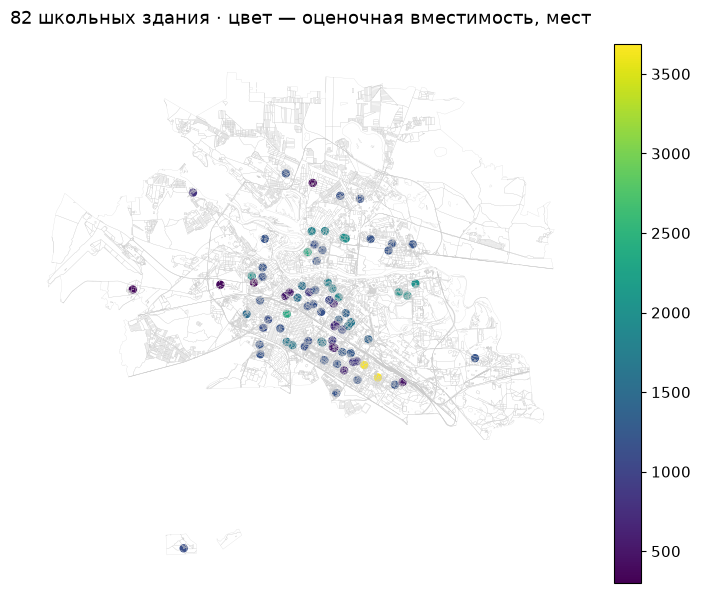

In [4]:
school_csv = pd.read_csv(DATA / "tyumen_schools_82.csv", sep=";")
assert len(schools) == len(school_csv) == 82 and schools.index.is_unique
assert int(schools.capacity.sum()) == int(results.capacity.sum()) == 106942
display(schools[["name","address","capacity","capacity_method","capacity_confidence"]].head(12))
display(school_csv["Метод оценки"].value_counts().rename("Зданий").to_frame())
print("82 здания; 106 942 оценочных места. Координаты и мощности сохранены из CSV.")
fig, ax = plt.subplots(figsize=(9,7)); blocks.boundary.plot(ax=ax,color="#cccccc",linewidth=.15)
schools.to_crs(blocks.crs).plot(ax=ax,column="capacity",markersize=25,cmap="viridis",legend=True)
ax.set_title("82 школьных здания · цвет — оценочная вместимость, мест"); ax.set_axis_off(); plt.show()

## 5. Пешеходная матрица
Матрица содержит минуты пути между 12 805 кварталами. Используется ранее сохранённый **пешеходный** граф; матрица не пересчитывается. Здесь проверяется схема Parquet без чтения всех 164 млн значений. Полная проверка ID и значений уже выполнена движком и отражена в отчётах задания 3.

In [5]:
matrix = pq.ParquetFile(DATA / "accessibility_matrix.parquet")
meta = matrix.metadata
fields = matrix.schema_arrow.names
index_metadata = json.loads(matrix.schema_arrow.metadata[b"pandas"])["index_columns"]
index_fields = {x for x in index_metadata if isinstance(x,str)}
value_fields = [x for x in fields if x not in index_fields]
assert meta.num_rows == 12805 and len(value_fields) == 12805
assert set(map(int,value_fields)) == set(results.index)
display(pd.DataFrame({"Значение":[meta.num_rows,len(value_fields),"минуты пешком",(DATA/"accessibility_matrix.parquet").stat().st_size]},index=["Строк", "Столбцов времён", "Единица", "Размер файла, байт"]))
print("Граф: graph.pkl. Его историческое происхождение — построение по локальному OSM, не готовый скачанный граф.")

,Значение
Строк,12805
Столбцов времён,12805
Единица,минуты пешком
"Размер файла, байт",332783645


Граф: graph.pkl. Его историческое происхождение — построение по локальному OSM, не готовый скачанный граф.


## 6. Обеспеченность и конкурентное распределение
Потребность — **120 мест на 1000 жителей**, с округлением вверх отдельно по кварталам. Доступность — **15 минут пешком**, самообслуживание включено, один диапазон доступности. Показатель обеспеченности — распределённые места / потребность квартала. Нулевая потребность даёт неопределённую обеспеченность, а не 0%. Конкурентное распределение часто даёт 0/1; это результат модели, а не фактическая вероятность попадания ребёнка в школу.

,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,0,0,0,0,0,0,0,0,NaN,NaN
1,0,0,0,0,0,0,0,0,NaN,NaN
2,51,0,51,0,0,0,0,0,0.0,0.0
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN
5,0,0,0,0,0,0,0,0,NaN,NaN
6,0,0,0,0,0,0,0,0,NaN,NaN
7,0,0,0,0,0,0,0,0,NaN,NaN
8,0,0,0,0,0,0,0,0,NaN,NaN
9,12,541,0,12,0,258,271,0,1.0,1.0


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
count,12805.000,12805.000,12805.000,12805.000,12805.0,12805.000,12805.000,12805.0,4630.000,4630.000
mean,11.404,8.352,4.233,7.171,0.0,1.181,6.909,0.0,0.383,0.383
std,38.187,117.946,22.564,31.529,0.0,31.943,101.851,0.0,0.485,0.485
min,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000,0.000
25%,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000,0.000
75%,3.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,1.000,1.000
max,1102.000,4005.000,1102.000,762.000,0.0,1662.000,3496.000,0.0,1.000,1.000


,source,target,value
0,14,327,15.0
1,22,10730,21.0
2,23,11237,38.0
3,24,10730,50.0
4,25,10730,5.0
5,26,11237,93.0
6,27,10730,16.0
7,28,10730,16.0
8,30,10730,17.0
9,34,9207,7.0


,Мест
Нормативная потребность,146028
Распределено в пределах 15 минут,91819
Остаточный дефицит,54209
Существующая оценочная вместимость,106942


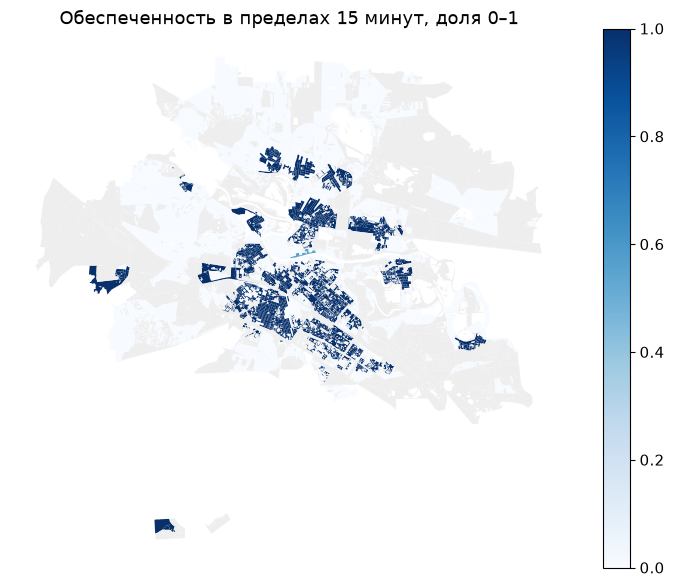

In [6]:
expected_demand = np.array([int(np.ceil(p/1000*120)) for p in results.population])
np.testing.assert_array_equal(provision.demand, expected_demand)
assert int(provision.demand.sum()) == 146028
assert int(provision.demand_within.sum()) == 91819
assert int(provision.demand_left.sum()) == 54209
assert ((provision.demand_within + provision.demand_left) == provision.demand).all()
display(provision.head(10))
display(provision.describe().round(3))
display(links.head(10))
display(pd.DataFrame({"Мест":[146028,91819,54209,106942]},index=["Нормативная потребность","Распределено в пределах 15 минут","Остаточный дефицит","Существующая оценочная вместимость"]))
fig, ax=plt.subplots(figsize=(9,7)); blocks.join(provision.provision_strong).plot(column="provision_strong",vmin=0,vmax=1,cmap="Blues",ax=ax,legend=True,missing_kwds={"color":"#eeeeee"},linewidth=0)
ax.set_title("Обеспеченность в пределах 15 минут, доля 0–1");ax.set_axis_off();plt.show()

## 7. Плотностные показатели
FSI — площадь этажей / площадь квартала; GSI — пятно зданий / площадь квартала; MXI — доля жилой площади; L — средняя этажность; OSR — открытое пространство относительно площади этажей. Площади — м², доли и индексы безразмерные. Плотность населения для дашборда дополнительно получена как население / площадь квартала в км².

D:\Рабочий стол\ITMO AI\python-package-boilerplate\.venv-blocksnet\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
D:\Рабочий стол\ITMO AI\python-package-boilerplate\.venv-blocksnet\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
site_area,12805.0,35123.612,262510.981,500.224,2229.434,6119.979,16397.100,1.680618e+07
footprint_area,12805.0,1738.105,5773.576,0.000,0.000,125.459,1592.468,1.673373e+05
build_floor_area,12805.0,4814.323,14258.942,0.000,0.000,126.419,2876.514,3.747171e+05
living_area,12805.0,2845.676,9549.431,0.000,0.000,0.000,809.702,2.758309e+05
non_living_area,12805.0,1968.647,8209.243,0.000,0.000,32.760,1035.417,1.844917e+05
fsi,12805.0,0.397,0.971,0.000,0.000,0.012,0.267,2.896200e+01
gsi,12805.0,0.109,0.164,0.000,0.000,0.012,0.170,1.000000e+00
mxi,7281.0,0.507,0.415,0.000,0.000,0.760,0.900,9.000000e-01
l,7281.0,2.936,3.824,1.000,1.000,1.000,3.000,2.400000e+01
osr,12805.0,inf,NaN,-0.683,2.923,82.467,NaN,inf


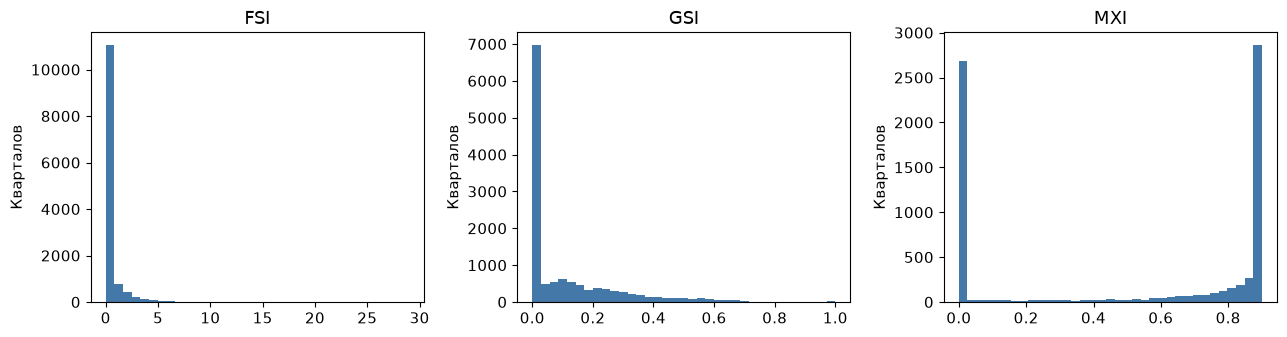

,"Плотность населения, чел./км²"
count,12805.000000
mean,8748.523044
std,28041.231064
min,0.000000
25%,0.000000
50%,0.000000
75%,1496.558354
max,868735.035032


In [7]:
pd.testing.assert_index_equal(density.index,results.index,check_names=False,exact=False)
display(density.describe().T.round(3))
fig, axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,key in zip(axes,["fsi","gsi","mxi"]):
    values=density[key].replace([np.inf,-np.inf],np.nan).dropna()
    ax.hist(values,bins=35,color="#4478a8");ax.set_title(key.upper());ax.set_ylabel("Кварталов")
plt.tight_layout();plt.show()
population_density = results.population / (blocks.area/1e6)
display(population_density.describe().rename("Плотность населения, чел./км²").to_frame())

## 8. Морфотипы и доступность территории
Spacematrix и Strelka характеризуют тип застройки по плотностным показателям, а не качество городской среды. Среднее время доступности территории (`area_accessibility`) измеряется в минутах. Неопределённые морфотипы кварталов без зданий не заменяются вымышленными значениями.

In [8]:
for filename in ["morphotypes_spacematrix.csv","morphotypes_spacematrix_clusters.csv","morphotypes_strelka.csv","area_accessibility.csv"]:
    frame=pd.read_csv(DATA/filename,index_col=0)
    print(filename, "строк:",len(frame),"поля:",list(frame.columns))
    display(frame.head(5))
for field in ["morphotype_spacematrix","morphotype_strelka"]:
    display(results[field].value_counts(dropna=False).rename("Кварталов").to_frame())
display(results.area_accessibility.describe().rename("Доступность, мин").to_frame())

morphotypes_spacematrix.csv строк: 12805 поля: ['l', 'fsi', 'mxi', 'cluster', 'morphotype']


,l,fsi,mxi,cluster,morphotype
0,1.057907,0.086720,0.000000,1.0,low-rise low-density non-residential
1,0.000000,0.000000,0.000000,NaN,NaN
2,1.082112,0.024541,0.623961,2.0,low-rise low-density residential
3,0.000000,0.000000,0.000000,NaN,NaN
4,0.000000,0.000000,0.000000,NaN,NaN


morphotypes_spacematrix_clusters.csv строк: 11 поля: ['l', 'fsi', 'mxi', 'l_interpretation', 'fsi_interpretation', 'mxi_interpretation', 'morphotype']


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,8.419657,1.520426,0.898867,high-mid-rise,NaN,residential,high-mid-rise residential
1,1.000000,0.201545,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
2,1.000000,0.080870,0.900000,low-rise,low-density,residential,low-rise low-density residential
3,17.000000,6.643868,0.900000,tower,high-density,residential,tower high-density residential
4,9.000000,2.484815,0.900000,high-mid-rise,high-density,residential,high-mid-rise high-density residential


morphotypes_strelka.csv строк: 12805 поля: ['l', 'fsi', 'mxi', 'morphotype']


,l,fsi,mxi,morphotype
0,1.057907,0.086720,0.000000,low-rise non-residential
1,0.000000,0.000000,0.000000,NaN
2,1.082112,0.024541,0.623961,individual residential
3,0.000000,0.000000,0.000000,NaN
4,0.000000,0.000000,0.000000,NaN


area_accessibility.csv строк: 12805 поля: ['area_accessibility']


,area_accessibility
id,
0,219.710436
1,221.045878
2,175.684720
3,179.121214
4,224.670579


,Кварталов
morphotype_spacematrix,
NaN,5524
low-rise low-density residential,2694
low-rise low-density non-residential,2672
mid-rise residential,619
high-mid-rise high-density residential,388
mid-rise non-residential,308
high-rise high-density residential,286
high-mid-rise residential,257
tower high-density residential,57


,Кварталов
morphotype_strelka,
NaN,5524
low-rise non-residential,2575
individual residential,1700
low-rise model,1380
high-rise modern microdistrict,642
mid-rise,469
central model,297
mid-rise non-residential,107
high-rise soviet microdistrict,62


,"Доступность, мин"
count,12805.000000
mean,175.206633
std,30.520526
min,138.174281
25%,153.011553
50%,166.648315
75%,188.972254
max,385.894357


## 9. Соответствие примеру BlocksNet и дашборду
Сверено с `aimclub/blocksnet/examples/pipeline.ipynb`, SHA `604140a26190b428a25903ee9beca3de548cf2a7`. Индексы ячеек исходного примера указаны с нуля. В установленной версии a9 отдельные пути импортов отличаются; используется сохранённая совместимая версия метода.

In [9]:
coverage = [
 ["Кварталы","3–12","2","Карта кварталов"], ["Землепользование и доли","15–22","2","Переключатель: землепользование и доли"],
 ["Матрица пути, мин","25–28","5","Производный показатель доступности; сама матрица — отдельный файл"],
 ["Здания и население","31–43","3","Население, площади, статус качества"], ["Школы и вместимость","46–53","4","82 точки, карточки, вместимость"],
 ["Обеспеченность и потоки","57–62","6","Обеспеченность, потребность и дефицит; потоки links — отдельная таблица"],
 ["Плотностные индексы","64","7","FSI, GSI, MXI, L, OSR и площади"], ["Spacematrix и кластеры","66–69","8","Морфотип Spacematrix; кластеры — сохранённая таблица"],
 ["Strelka","71–73","8","Морфотип Strelka"], ["Area accessibility","75–76","8","Среднее время доступности"]]
display(pd.DataFrame(coverage,columns=["Группа показателей","Ячейки примера","Раздел этого ноутбука","Где в дашборде / сохранённых результатах"]))

,Группа показателей,Ячейки примера,Раздел этого ноутбука,Где в дашборде / сохранённых результатах
0,Кварталы,3–12,2,Карта кварталов
1,Землепользование и доли,15–22,2,Переключатель: землепользование и доли
2,"Матрица пути, мин",25–28,5,Производный показатель доступности; сама матри...
3,Здания и население,31–43,3,"Население, площади, статус качества"
4,Школы и вместимость,46–53,4,"82 точки, карточки, вместимость"
5,Обеспеченность и потоки,57–62,6,"Обеспеченность, потребность и дефицит; потоки ..."
6,Плотностные индексы,64,7,"FSI, GSI, MXI, L, OSR и площади"
7,Spacematrix и кластеры,66–69,8,Морфотип Spacematrix; кластеры — сохранённая т...
8,Strelka,71–73,8,Морфотип Strelka
9,Area accessibility,75–76,8,Среднее время доступности


## 10. Выводы и повторное открытие

1. Модельное население после восстановления жилья — **1 197 166**, ранее 980 707. Это изменение распознавания застройки и модели, а не демографический рост.
2. Вместимость **82 зданий — 106 942 места**, значения индивидуальные и разной достоверности; прежние одинаковые 250 мест больше не используются.
3. При нормативной потребности **146 028** модель распределяет **91 819** мест; дефицит — **54 209**. Соседство со школой не гарантирует получение мест из-за конкуренции.
4. Неопределённое население и пустые участки OSM нужно отличать от подтверждённого отсутствия жилья. Границы кварталов и пешеходная сеть остались прежними.
5. Задание 3 использует именно эту исправленную базу: А, Б и В уменьшают дефицит на 600 мест до 53 609. Полный поиск завершён, 12 805 вариантов, ошибок 0; А входит в 2 877 равноценных лучших.

Готовый HTML: `data_tyumen/dashboard_refined.html`; в приложении: <http://127.0.0.1:8767/practice2>. Для пересборки HTML из сохранённых результатов запустите существующим Python `examples/tyumen_dashboard_refined.py` — это визуализация, не новый расчёт модели. Повторный запуск **этого** ноутбука только читает результаты. Код исторического полного пайплайна сохранён отдельно; текущие скрипты пересчёта перечислены в начале. Перед изменением данных сделайте копию: задания 3 привязаны к их подписи.